In [17]:
# =========================================
# LAB 04 - TRATAMIENTO DE DATOS Y CLUSTERING
# Elbow Plot + Silhouette + Dendrogram
# Google Colab Ready
# =========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import dendrogram, linkage

sns.set(style="whitegrid")
np.random.seed(42)

In [18]:
# Generate synthetic dataset (two interleaving moons)
X, y = make_moons(n_samples=500, noise=0.05)

df = pd.DataFrame(X, columns=["Feature_1", "Feature_2"])
df.head()

,Feature_1,Feature_2
0,0.830586,-0.447733
1,0.701678,0.816918
2,1.022080,-0.492571
3,-0.316765,0.953438
4,0.293226,1.057185


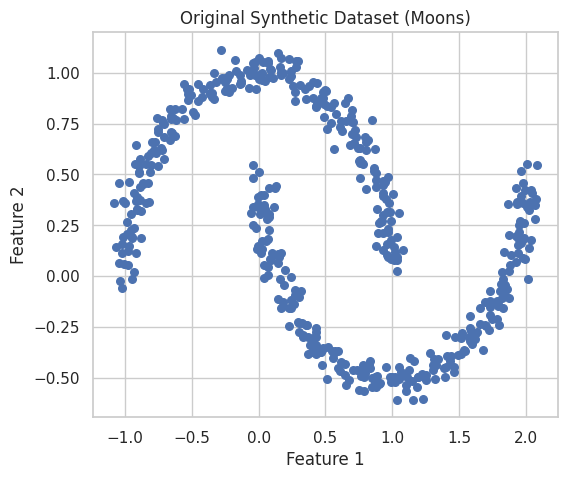

In [19]:
# Plot original data
plt.figure(figsize=(6, 5))
plt.scatter(df["Feature_1"], df["Feature_2"], s=30)
plt.title("Original Synthetic Dataset (Moons)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# Data Scaling

In [20]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

Why scaling?
Clustering uses distance. If features are on different scales, one dominates the distance calculation and ruins clustering.

# Elbow Method (Choosing K)

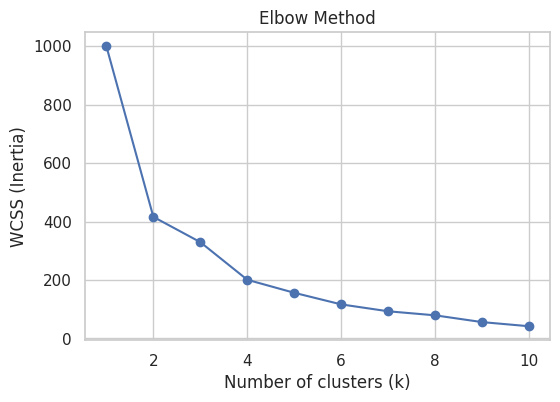

In [21]:
wcss = []

K_range = range(1, 11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(K_range, wcss, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of clusters (k)")
plt.ylabel("WCSS (Inertia)")
plt.show()

Theory (Elbow):
WCSS = within-cluster sum of squares
We look for a bend where adding more clusters gives diminishing improvement.

# Silhouette Analysis (Quality of Clustering)

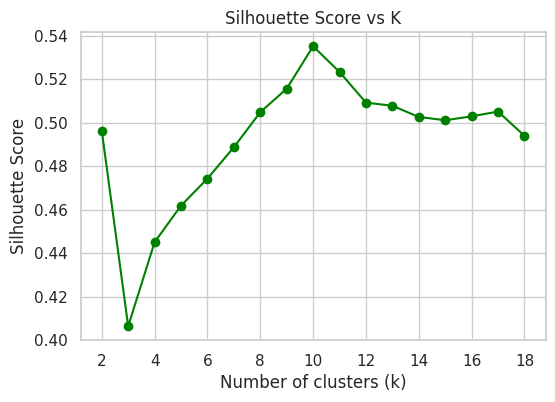

In [22]:
sil_scores = []

for k in range(2, 19):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    sil_scores.append(score)

plt.figure(figsize=(6, 4))
plt.plot(range(2, 19), sil_scores, marker='o', color='green')
plt.title("Silhouette Score vs K")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.show()

Theory (Silhouette):

Close to 1 → good clustering

Around 0 → overlapping clusters

Negative → wrong clustering
The best K usually has the highest silhouette score.

## K-Means Clustering (Final Model)

In [23]:
k = 2  # You can justify this choice using Elbow + Silhouette
kmeans = KMeans(n_clusters=k, random_state=42)
labels = kmeans.fit_predict(X_scaled)

df["Cluster"] = labels

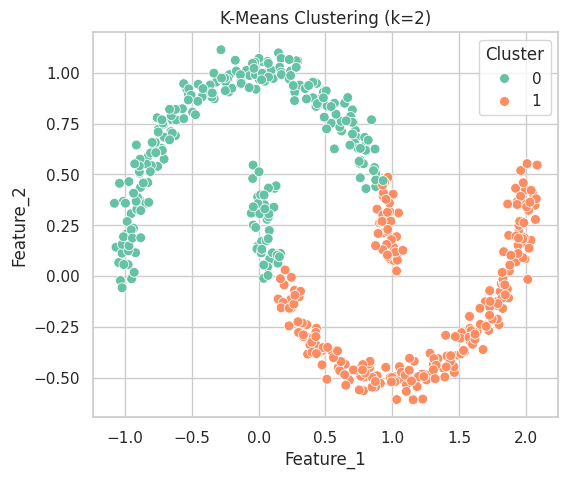

In [24]:
plt.figure(figsize=(6, 5))
sns.scatterplot(
    x=df["Feature_1"],
    y=df["Feature_2"],
    hue=df["Cluster"],
    palette="Set2",
    s=50
)
plt.title(f"K-Means Clustering (k={k})")
plt.show()

K-Means tries to form spherical clusters → moons shape is not ideal for K-Means, which is good to mention as a scientific limitation.

# Hierarchical Clustering + Dendrogram

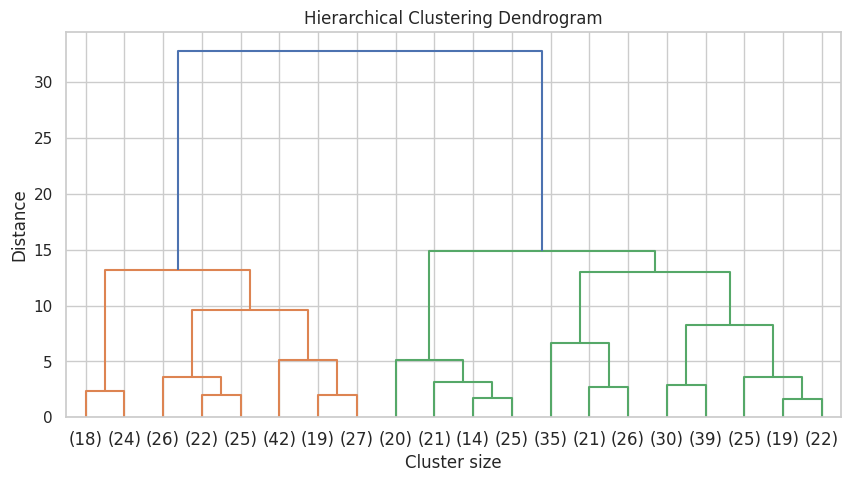

In [25]:
# Linkage matrix (Ward minimizes variance inside clusters)
linked = linkage(X_scaled, method="ward")

plt.figure(figsize=(10, 5))
dendrogram(linked, truncate_mode="lastp", p=20)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Cluster size")
plt.ylabel("Distance")
plt.show()

Theory (Dendrogram):

Shows how samples merge step by step

Large vertical jumps → natural separation

You cut the dendrogram at a height to choose number of clusters